## Training of the descriptors-only classifier and the embeddings-only classifier on the 1st level

In [ ]:
import os
from pathlib import Path
import random
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from keras import layers, losses, optimizers, models, metrics, callbacks
from keras.callbacks import EarlyStopping
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, roc_auc_score, classification_report
from tensorflow.keras.utils import register_keras_serializable
import keras_tuner
from keras_tuner import RandomSearch, Hyperband, BayesianOptimization

In [ ]:
current_dir = Path.cwd()

In [ ]:
desc_dim = 887
emb_dim = 1024
batch_size = 32
epoch = 100
dtype = tf.float32
ptf_path = str(current_dir.parent / 'datasets/First Level/pre_processed/train_feat.npy')
pte_path = str(current_dir.parent / 'datasets/First Level/pre_processed/train_emb.npy')
pvf_path = str(current_dir.parent / 'datasets/First Level/pre_processed/valid_feat.npy')
pve_path = str(current_dir.parent / 'datasets/First Level/pre_processed/valid_emb.npy')
y_train_path = str(current_dir.parent / 'datasets/First Level/y_train.npy')
y_valid_path = str(current_dir.parent / 'datasets/First Level/y_valid.npy')
model_e_dir = str(current_dir.parent / 'models/First_Level/untrained_embedding_model.keras')
model_d_dir = str(current_dir.parent / 'models/First_Level/untrained_descriptores_model.keras')

In [ ]:
test_emb_dir = str(current_dir.parent / 'datasets/First Level/pre_processed/test_emb.npy')
test_feat_dir = str(current_dir.parent / 'datasets/First Level/pre_processed/test_feat.npy')
y_test_dir = str(current_dir.parent / 'datasets/First Level/y_test.npy')

In [4]:
def set_reproducibility(seed=42):
    # 1. Fijar semilla en Python core
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    keras.utils.set_random_seed(seed)
set_reproducibility()
tf.keras.mixed_precision.set_global_policy('float64')

In [4]:
def reset_weigths(model: models.Model):
    for layer in model.layers:
        if hasattr(layer, 'kernel_initializer'):
            layer.kernel.assign(layer.kernel_initializer(shape=layer.kernel.shape, dtype=layer.kernel.dtype))
        if hasattr(layer, 'bias_initializer') and layer.use_bias:
            layer.bias.assign(layer.bias_initializer(shape=layer.bias.shape, dtype=layer.bias.dtype))
        if hasattr(layer, 'moving_mean'):
            layer.moving_mean.assign(tf.zeros_like(layer.moving_mean))
        if hasattr(layer, 'moving_variance'):
            layer.moving_variance.assign(tf.ones_like(layer.moving_variance))
def load_untrained_model(model_dir):
    model = models.load_model(str(model_dir))
    reset_weigths(model)
    return model

### Embeddings-only classifier

In [5]:
X_train = np.load(pte_path)
X_valid = np.load(pve_path)
y_train = np.load(y_train_path)
y_valid = np.load(y_valid_path)
train_d = tf.data.Dataset.from_tensor_slices(
    (X_train.astype('float32'), y_train.reshape((-1, 1)))
).batch(batch_size)
valid_d = tf.data.Dataset.from_tensor_slices(
    (X_valid.astype('float32'), y_valid.reshape((-1, 1)))
).batch(batch_size)

In [6]:
model: models.Model = load_untrained_model(model_e_dir)
model.summary()

c:\Users\Victor\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 22 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "enzyme_classifier_embedding"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gaussian_noise_1                │ (None, 1024)           │             0 │
│ (GaussianNoise)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 320)            │       328,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 320)            │         1,280 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 320)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 320)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 160)            │        51,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 160)            │           640 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 160)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 160)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │           161 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,142,405 (4.36 MB)

 Trainable params: 380,481 (1.45 MB)

 Non-trainable params: 960 (3.75 KB)

 Optimizer params: 760,964 (2.90 MB)

In [7]:
def build_model(hp) -> keras.Model:
    input_emb = layers.Input(shape=(emb_dim,), dtype=dtype)
    
    dropout_rate = hp.Float('dropout_rate', min_value=0.1, max_value=0.5, step=0.1)
    activation = hp.Choice('activation', values=['relu', 'swish', 'leaky_relu', 'elu'])
    l2_reg = hp.Float('l2_reg', min_value=1e-5, max_value=1e-2, sampling='log')
    noise_std = hp.Float('noise_std', min_value=0.01, max_value=0.1, step=0.03)

    noisy_emb = layers.GaussianNoise(noise_std)(input_emb)

    y = noisy_emb
    units_e = hp.Int(f'emb_units_start', min_value=64, max_value=768, step=64)
    for i in range(hp.Int('emb_layers', 1, 5)):
        y = layers.Dense(units_e // (1 << i), kernel_regularizer=keras.regularizers.l2(l2_reg), dtype=dtype)(y)
        y = layers.BatchNormalization()(y)
        y = layers.Activation(activation)(y)
        y = layers.Dropout(dropout_rate)(y)

    output = layers.Dense(1, activation='sigmoid', dtype=dtype)(y)
    model = models.Model(inputs=input_emb, outputs=output, name='enzyme_classifier_embedding')
    learning_rate = hp.Float('learning_rate', min_value=1e-5, max_value=1e-3, sampling='log')
    
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss=keras.losses.BinaryCrossentropy(label_smoothing=0.1),
        metrics=[
            'accuracy', 
            keras.metrics.Precision(name='precision'), 
            keras.metrics.Recall(name='recall')
        ]
    )
    return model
tuner = Hyperband(
        build_model,
        objective = "val_loss",
        max_epochs=50,
        factor=3,
        seed=42,
        directory='tunning_FL',
        project_name='enzyme_embedding_branch'
    )
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Best Hyperparameters:")
lr = 0.0001
for param in best_hp.values:
    print(f"{param}: {best_hp.get(param)}")
    if param == 'learning_rate':
        lr = best_hp.get(param)

Reloading Tuner from tunning_FL\enzyme_embedding_branch\tuner0.json
Best Hyperparameters:
dropout_rate: 0.2
activation: relu
l2_reg: 1.9454646475567588e-05
noise_std: 0.01
emb_units_start: 320
emb_layers: 2
learning_rate: 4.039016495327903e-05
tuner/epochs: 50
tuner/initial_epoch: 0
tuner/bracket: 0
tuner/round: 0


#### Training process

In [ ]:
from typing import Any
class Classifier(keras.Model):
    def __init__(self, model: keras.Model, loss, **kwargs: Any) -> None:
        super(Classifier, self).__init__(**kwargs)
        self.model = model
        self.current_loss = loss
        self.total_loss_tracker = metrics.Mean(name="loss")
        self.accuracy_tracker = metrics.Accuracy(name='accuracy')
    
    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.accuracy_tracker
        ]
    
    def call(self, inputs) -> Any:
        return self.model(inputs)
    
    def train_step(self, data):
        X, y = data
        with tf.GradientTape() as tape:
            pred = self(X)
            loss = self.current_loss(y, pred)
        grads = tape.gradient(loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.trainable_variables))
        self.total_loss_tracker.update_state(loss)
        self.accuracy_tracker.update_state(y, tf.round(pred))
        return {m.name: m.result() for m in self.metrics}
    
    def test_step(self, data):
        X, y = data
        pred = self(X)
        loss = self.current_loss(y, pred)
        self.total_loss_tracker.update_state(loss)
        self.accuracy_tracker.update_state(y, tf.round(pred))
        return {m.name: m.result() for m in self.metrics}

def train(train_data: tf.data.Dataset, valid_data: tf.data.Dataset, model: models.Model) -> None:
    optimizer = optimizers.Adam(0.0001, clipnorm=1.0)
    loss = losses.binary_crossentropy
    ea = callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    )
    logger = callbacks.CSVLogger(str(current_dir.parent / 'notebooks/history_1l_emb.csv'))
    """
    rlr = tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', 
        factor=0.5,
        patience=3, 
        min_lr=1e-6,
        verbose=1
    )
    """
    classifier = Classifier(model, loss)
    classifier.compile(optimizer)
    classifier.fit(train_data, batch_size=batch_size, epochs=epoch, callbacks=[ea, logger], validation_data=valid_data)
    classifier.model.save(str(current_dir.parent / 'models/First_Level/embedding_model.keras'))
    print('Training process completed')

In [9]:
train(train_d, valid_d, model)

Epoch 1/100
12401/12401 ━━━━━━━━━━━━━━━━━━━━ 133s 10ms/step - accuracy: 0.8518 - loss: 0.3466 - val_accuracy: 0.8777 - val_loss: 0.2934
Epoch 2/100
12401/12401 ━━━━━━━━━━━━━━━━━━━━ 120s 10ms/step - accuracy: 0.8924 - loss: 0.2657 - val_accuracy: 0.8987 - val_loss: 0.2493
Epoch 3/100
12401/12401 ━━━━━━━━━━━━━━━━━━━━ 124s 10ms/step - accuracy: 0.9083 - loss: 0.2310 - val_accuracy: 0.9086 - val_loss: 0.2296
Epoch 4/100
12401/12401 ━━━━━━━━━━━━━━━━━━━━ 123s 10ms/step - accuracy: 0.9186 - loss: 0.2079 - val_accuracy: 0.9124 - val_loss: 0.2244
Epoch 5/100
12401/12401 ━━━━━━━━━━━━━━━━━━━━ 123s 10ms/step - accuracy: 0.9264 - loss: 0.1907 - val_accuracy: 0.9170 - val_loss: 0.2163
Epoch 6/100
12401/12401 ━━━━━━━━━━━━━━━━━━━━ 123s 10ms/step - accuracy: 0.9320 - loss: 0.1773 - val_accuracy: 0.9208 - val_loss: 0.2149
Epoch 7/100
12401/12401 ━━━━━━━━━━━━━━━━━━━━ 120s 10ms/step - accuracy: 0.9369 - loss: 0.1662 - val_accuracy: 0.9253 - val_loss: 0.2057
Epoch 8/100
12401/12401 ━━━━━━━━━━━━━━━━━━━━ 120

In [ ]:
model: models.Model = models.load_model(str(current_dir.parent / 'models/First_Level/embedding_model.keras'))

In [6]:
X_train = np.load(pte_path)
X_valid = np.load(pve_path)
y_train = np.load(y_train_path)
y_valid = np.load(y_valid_path)

In [7]:
pred_train = model.predict(X_train)
pred_valid = model.predict(X_valid)
pred_train = (pred_train > 0.5).astype(int)
pred_valid = (pred_valid > 0.5).astype(int)

12401/12401 ━━━━━━━━━━━━━━━━━━━━ 34s 3ms/step
689/689 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step


In [8]:
y_train = y_train.reshape((-1, 1))
y_valid = y_valid.reshape((-1, 1))

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
def plot_con_matrix(matrix, class_labels, title):  
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=True, square=True, linewidths=0.5, annot_kws={'size': 12})
    plt.xlabel('Prediccion')
    plt.ylabel('Valor Real')
    plt.title(title)
    plt.xticks(ticks=np.arange(len(class_labels)) + 0.5, labels=class_labels)
    plt.yticks(ticks=np.arange(len(class_labels)) + 0.5, labels=class_labels, rotation=0)
    plt.tight_layout()
    plt.show()

Accuracy training: 0.9445
Accuracy test: 0.9326
Precision training: 0.9539
Precision test: 0.9387
Recall training: 0.9125
Recall test: 0.8988
AUC training: 0.9402
AUC test: 0.9281
F1-score training: 0.9327
F1-score test: 0.9183
Clasification report training:
              precision    recall  f1-score   support

         0.0       0.94      0.97      0.95    229595
         1.0       0.95      0.91      0.93    167237

    accuracy                           0.94    396832
   macro avg       0.95      0.94      0.94    396832
weighted avg       0.94      0.94      0.94    396832

Clasification report test:
              precision    recall  f1-score   support

           0       0.93      0.96      0.94     12756
           1       0.94      0.90      0.92      9291

    accuracy                           0.93     22047
   macro avg       0.93      0.93      0.93     22047
weighted avg       0.93      0.93      0.93     22047



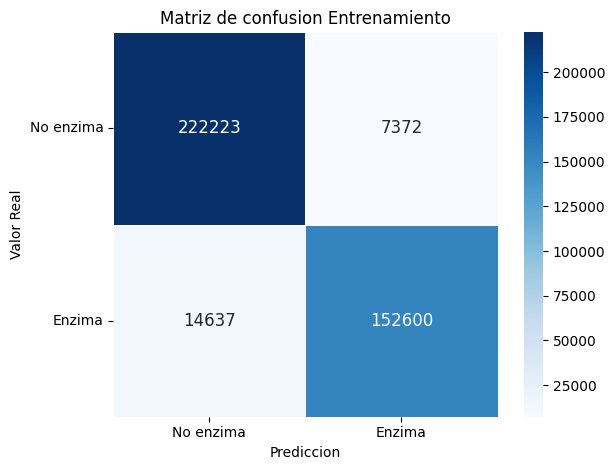

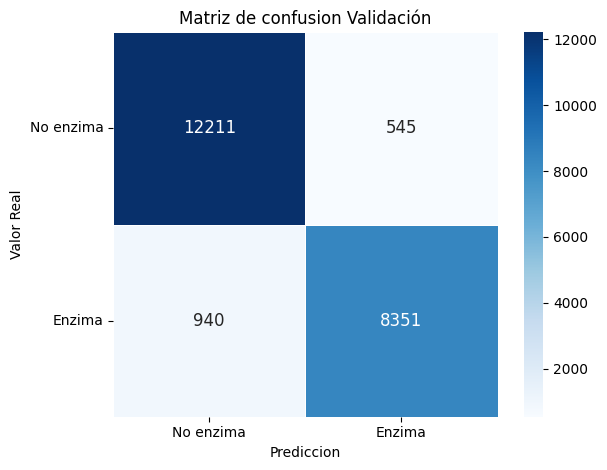

In [10]:
accuracy_t = accuracy_score(y_train, pred_train)
accuracy_v = accuracy_score(y_valid, pred_valid)
precision_t = precision_score(y_train, pred_train)
precision_v = precision_score(y_valid, pred_valid)
recall_t = recall_score(y_train, pred_train)
recall_v = recall_score(y_valid, pred_valid)
roc_auc_t = roc_auc_score(y_train, pred_train)
roc_auc_v = roc_auc_score(y_valid, pred_valid)
f1_t = f1_score(y_train, pred_train)
f1_v = f1_score(y_valid, pred_valid)
conf_matrix_t = confusion_matrix(y_train, pred_train)
conf_matrix_v = confusion_matrix(y_valid, pred_valid)
print(f"Accuracy training: {accuracy_t:.4f}")
print(f"Accuracy test: {accuracy_v:.4f}")
print(f"Precision training: {precision_t:.4f}")
print(f"Precision test: {precision_v:.4f}")
print(f"Recall training: {recall_t:.4f}")
print(f"Recall test: {recall_v:.4f}")
print(f'AUC training: {roc_auc_t:.4f}')
print(f'AUC test: {roc_auc_v:.4f}')
print(f"F1-score training: {f1_t:.4f}")
print(f"F1-score test: {f1_v:.4f}")
print("Clasification report training:", classification_report(y_train, pred_train), sep=f'\n')
print("Clasification report test:", classification_report(y_valid, pred_valid), sep=f'\n')
class_labels = ['No enzima', 'Enzima']
plot_con_matrix(conf_matrix_t, class_labels, 'Matriz de confusion Entrenamiento')
plot_con_matrix(conf_matrix_v, class_labels, 'Matriz de confusion Validación')

In [8]:
X_test = np.load(test_emb_dir)
y_test = np.load(y_test_dir)

689/689 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step
Accuracy test: 0.9338
Clasification report test:
              precision    recall  f1-score   support

           0       0.93      0.96      0.94     12755
           1       0.94      0.90      0.92      9291

    accuracy                           0.93     22046
   macro avg       0.93      0.93      0.93     22046
weighted avg       0.93      0.93      0.93     22046



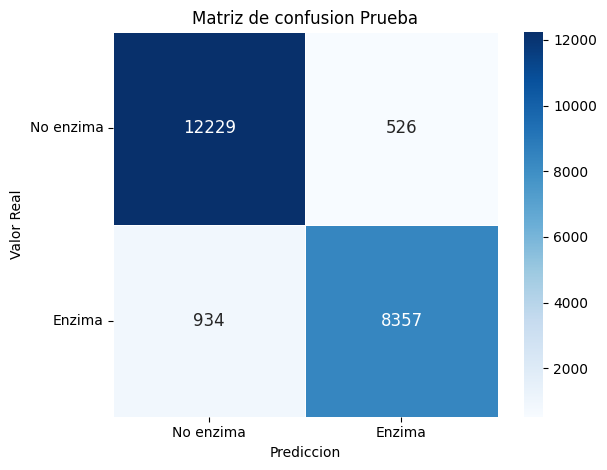

In [12]:
pred_test = model.predict(X_test)
pred_test = (pred_test > 0.5).astype(int)
y_test = y_test.reshape((-1, 1))
acc_t = accuracy_score(y_test, pred_test)
conf_matrix_t = confusion_matrix(y_test, pred_test)
class_labels = ['No enzima', 'Enzima']
print(f"Accuracy test: {acc_t:.4f}")
print("Clasification report test:", classification_report(y_test, pred_test), sep=f'\n')
plot_con_matrix(conf_matrix_t, class_labels, 'Matriz de confusion Prueba')

In [ ]:
history = pd.read_csv(str(current_dir.parent / 'notebooks/history_1l_emb.csv'))
history.head(10)

,epoch,accuracy,loss,val_accuracy,val_loss
0,0,0.851811,0.346563,0.877716,0.293405
1,1,0.892426,0.265704,0.898671,0.249290
2,2,0.908301,0.231039,0.908650,0.229649
3,3,0.918610,0.207888,0.912414,0.224385
4,4,0.926359,0.190708,0.917041,0.216341
5,5,0.932039,0.177271,0.920806,0.214924
6,6,0.936895,0.166185,0.925251,0.205731
7,7,0.941038,0.157064,0.925296,0.213481
8,8,0.944579,0.149132,0.928290,0.205376
9,9,0.947328,0.142987,0.932644,0.200592


In [12]:
from matplotlib.ticker import MaxNLocator
def plot_charts(history: pd.DataFrame, metrics: tuple[str, str], labels: tuple[str, str]):
    epochs = history['epoch'].to_numpy() + 1 if 'epoch' in history.columns else np.arange(1, len(history) + 1)

    best_val_loss_idx = history[f'val_{metrics[0]}'].idxmin()
    best_val_acc_idx = history[f'val_{metrics[1]}'].idxmax()

    train_color = '#1f77b4'
    valid_color = '#d62728'
    highlight_color = '#222222'

    sns.set_theme(style='whitegrid', context='paper')
    plt.rcParams.update({
        'font.size': 11,
        'axes.titlesize': 13,
        'axes.labelsize': 11,
        'legend.fontsize': 10,
        'xtick.labelsize': 10,
        'ytick.labelsize': 10,
        'axes.spines.top': False,
        'axes.spines.right': False,
    })

    fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), dpi=180, constrained_layout=True)

    metric_specs = [
        {
            'ax': axes[0],
            'train_key': metrics[0],
            'valid_key': f'val_{metrics[0]}',
            'title': f'{labels[0]} del entrenamiento y validación',
            'ylabel': labels[0],
            'best_idx': best_val_loss_idx,
        },
        {
            'ax': axes[1],
            'train_key': metrics[1],
            'valid_key': f'val_{metrics[1]}',
            'title': f'{labels[1]} del entrenamiento y validación',
            'ylabel': labels[1],
            'best_idx': best_val_acc_idx,
        },
    ]

    for spec in metric_specs:
        ax = spec['ax']
        train_values = history[spec['train_key']].to_numpy()
        valid_values = history[spec['valid_key']].to_numpy()
        best_epoch = int(epochs[spec['best_idx']])
        best_value = valid_values[spec['best_idx']]

        ax.plot(epochs, train_values, color=train_color, lw=2.2, label='Entrenamiento')
        ax.plot(epochs, valid_values, color=valid_color, lw=2.2, ls='--', label='Validación')
        ax.scatter(best_epoch, best_value, color=highlight_color, s=38, zorder=5)
        ax.axvline(best_epoch, color=highlight_color, lw=1.0, ls=':', alpha=0.8)
        '''
        ax.annotate(
            f"Época {best_epoch}\n{best_value:.4f}",
            xy=(best_epoch, best_value),
            xytext=(10, 12),
            textcoords='offset points',
            fontsize=9,
            color=highlight_color,
            bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#444444', alpha=0.95),
            arrowprops=dict(arrowstyle='->', color=highlight_color, lw=0.9),
        )
        '''

        ax.set_title(spec['title'], pad=10, weight='bold')
        ax.set_xlabel('Época')
        ax.set_ylabel(spec['ylabel'])
        ax.set_xlim(epochs.min(), epochs.max())
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(True, which='major', color='#d9d9d9', lw=0.8)
        ax.grid(True, which='minor', color='#efefef', lw=0.5, alpha=0.7)
        ax.minorticks_on()
        ax.tick_params(axis='both', which='major', length=5, width=0.8)
        ax.legend(loc='best', frameon=True, framealpha=0.95, edgecolor='#d0d0d0')

    axes[0].text(
        0.02,
        0.98,
        f"{labels[0]} final del entrenamiento: {history[metrics[0]].iloc[-1]:.4f}\n{labels[0]} final validación: {history[f'val_{metrics[0]}'].iloc[-1]:.4f}",
        transform=axes[0].transAxes,
        va='top',
        fontsize=9,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#d0d0d0', alpha=0.95),
    )

    axes[1].text(
        0.02,
        0.98,
        f"{labels[1]} final entrenamiento: {history[metrics[1]].iloc[-1]:.4f}\n{labels[1]} final validación: {history[f'val_{metrics[1]}'].iloc[-1]:.4f}",
        transform=axes[1].transAxes,
        va='top',
        fontsize=9,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#d0d0d0', alpha=0.95),
    )

    fig.suptitle('Curvas de aprendizaje del modelo', fontsize=15, weight='bold', y=1.03)
    sns.despine(fig=fig)
    plt.show()

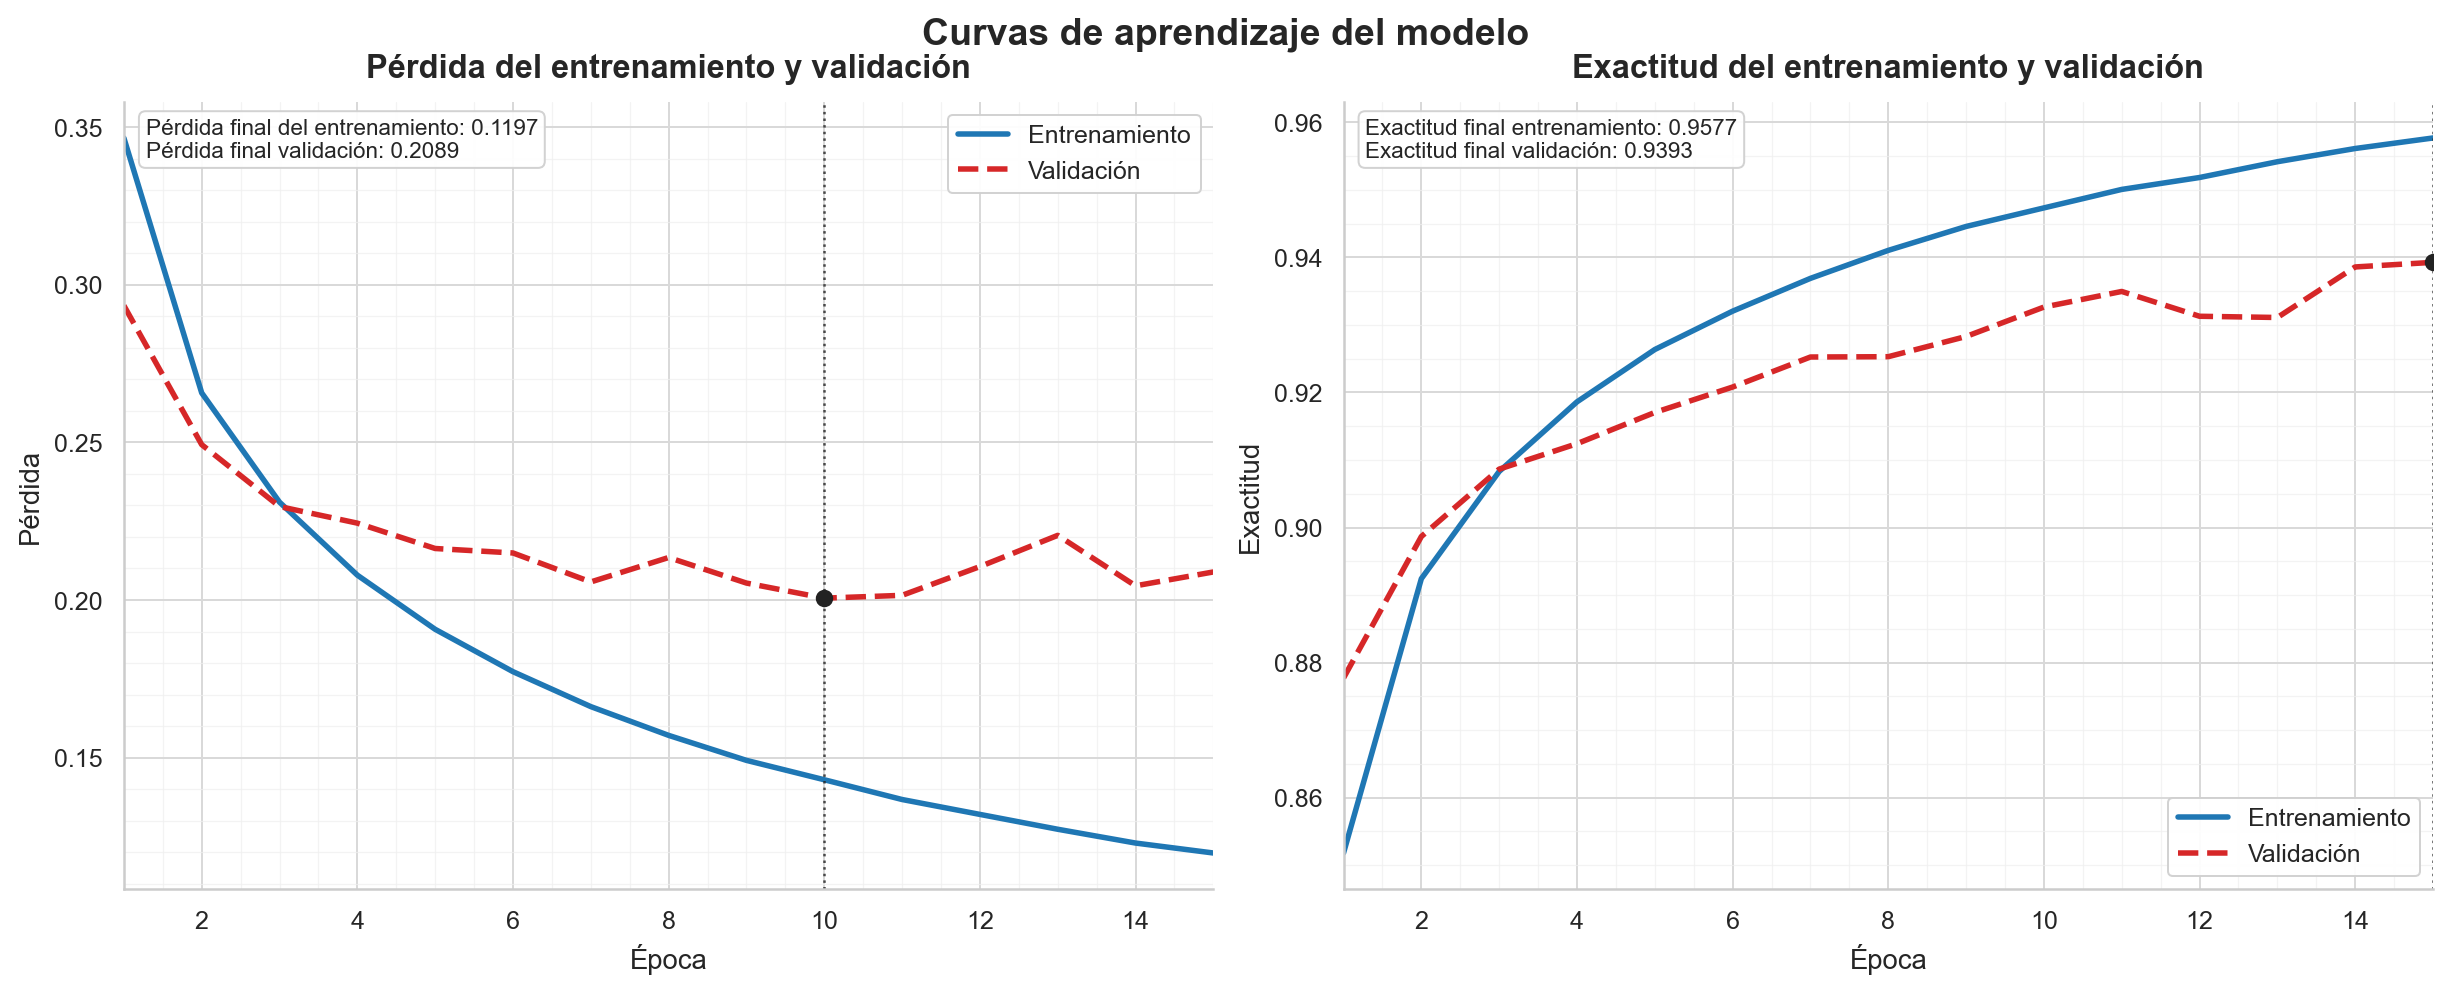

In [13]:
plot_charts(history, ('loss', 'accuracy'), ('Pérdida', 'Exactitud'))

### Descriptores-only classifier

In [5]:
X_train = np.load(ptf_path)
X_valid = np.load(pvf_path)
y_train = np.load(y_train_path)
y_valid = np.load(y_valid_path)
train_d = tf.data.Dataset.from_tensor_slices(
    (X_train.astype('float32'), y_train.reshape((-1, 1)))
).batch(batch_size)
valid_d = tf.data.Dataset.from_tensor_slices(
    (X_valid.astype('float32'), y_valid.reshape((-1, 1)))
).batch(batch_size)

In [6]:
model: models.Model = load_untrained_model(model_d_dir)
model.summary()

c:\Users\Victor\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\saving\saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 14 variables whereas the saved optimizer has 2 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Model: "enzyme_classifier_descriptores"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 887)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gaussian_noise_1                │ (None, 887)            │             0 │
│ (GaussianNoise)                 │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        56,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 171,205 (668.77 KB)

 Trainable params: 57,025 (222.75 KB)

 Non-trainable params: 128 (512.00 B)

 Optimizer params: 114,052 (445.52 KB)

In [7]:
def build_model(hp) -> keras.Model:
    input_desc = layers.Input(shape=(desc_dim,), dtype=dtype)
    dropout_rate = hp.Float('dropout_rate', min_value=0.1, max_value=0.5, step=0.1)
    activation = hp.Choice('activation', values=['relu', 'swish', 'leaky_relu', 'elu'])
    l2_reg = hp.Float('l2_reg', min_value=1e-5, max_value=1e-2, sampling='log')
    noise_std = hp.Float('noise_std', min_value=0.01, max_value=0.1, step=0.03)

    noisy_desc = layers.GaussianNoise(noise_std)(input_desc)

    #y = input_emb
    y = noisy_desc
    units_e = hp.Int(f'desc_units_start', min_value=64, max_value=768, step=64)
    for i in range(hp.Int('desc_layers', 1, 5)):
        y = layers.Dense(units_e // (1 << i), kernel_regularizer=keras.regularizers.l2(l2_reg), dtype=dtype)(y)
        y = layers.BatchNormalization()(y)
        y = layers.Activation(activation)(y)
        y = layers.Dropout(dropout_rate)(y)

    z = layers.Dense(7)(y)
    output = layers.Activation('softmax')(z)
    model = models.Model(input_desc, output, name='classifier_2l_descriptores_only')
    learning_rate = hp.Float('learning_rate', min_value=1e-6, max_value=1e-3, sampling='log')
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss='categorical_crossentropy',
        metrics=[metrics.AUC(curve='ROC', multi_label=True), metrics.F1Score(average='macro')]
    )
    return model

tuner = Hyperband(
        build_model,
        objective = "val_loss",
        max_epochs=50,
        factor=3,
        seed=42,
        directory='tunning_FL',
        project_name='enzyme_descriptores_branch'
    )
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]
print("Best Hyperparameters:")
lr = 0.0001
for param in best_hp.values:
    print(f"{param}: {best_hp.get(param)}")
    if param == 'learning_rate':
        lr = best_hp.get(param)

Reloading Tuner from tunning_FL\enzyme_descriptores_branch\tuner0.json
Best Hyperparameters:
dropout_rate: 0.4
activation: leaky_relu
l2_reg: 1.4419025004199698e-05
noise_std: 0.04
desc_units_start: 64
desc_layers: 1
learning_rate: 0.0003371034125137774
tuner/epochs: 50
tuner/initial_epoch: 17
tuner/bracket: 3
tuner/round: 3
tuner/trial_id: 0047


#### Training process

In [ ]:
from typing import Any
class Classifier(keras.Model):
    def __init__(self, model: keras.Model, loss, **kwargs: Any) -> None:
        super(Classifier, self).__init__(**kwargs)
        self.model = model
        self.current_loss = loss
        self.total_loss_tracker = metrics.Mean(name="loss")
        self.accuracy_tracker = metrics.Accuracy(name='accuracy')
    
    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.accuracy_tracker
        ]
    
    def call(self, inputs) -> Any:
        return self.model(inputs)
    
    def train_step(self, data):
        X, y = data
        with tf.GradientTape() as tape:
            pred = self(X)
            loss = self.current_loss(y, pred)
        grads = tape.gradient(loss, self.trainable_variables)
        self.optimizer.apply_gradients(zip(grads, self.trainable_variables))
        self.total_loss_tracker.update_state(loss)
        self.accuracy_tracker.update_state(y, tf.round(pred))
        return {m.name: m.result() for m in self.metrics}
    
    def test_step(self, data):
        X, y = data
        pred = self(X)
        loss = self.current_loss(y, pred)
        self.total_loss_tracker.update_state(loss)
        self.accuracy_tracker.update_state(y, tf.round(pred))
        return {m.name: m.result() for m in self.metrics}

def train(train_data: tf.data.Dataset, valid_data: tf.data.Dataset, model: models.Model) -> None:
    optimizer = optimizers.Adam(0.0001, clipnorm=1.0)
    loss = losses.binary_crossentropy
    ea = callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True
    )
    logger = callbacks.CSVLogger(str(current_dir.parent / 'notebooks/history_1l_feat.csv'))
    """
    rlr = tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_loss', 
        factor=0.5,
        patience=3, 
        min_lr=1e-6,
        verbose=1
    )
    """
    classifier = Classifier(model, loss)
    classifier.compile(optimizer)
    classifier.fit(train_data, batch_size=batch_size, epochs=epoch, callbacks=[ea, logger], validation_data=valid_data)
    classifier.model.save(str(current_dir.parent / 'models/First_Level/descriptores_model.keras'))
    print('Training process completed')

In [9]:
train(train_d, valid_d, model)

Epoch 1/100
12401/12401 ━━━━━━━━━━━━━━━━━━━━ 78s 5ms/step - accuracy: 0.8192 - loss: 0.4129 - val_accuracy: 0.8436 - val_loss: 0.3639
Epoch 2/100
12401/12401 ━━━━━━━━━━━━━━━━━━━━ 48s 4ms/step - accuracy: 0.8574 - loss: 0.3466 - val_accuracy: 0.8642 - val_loss: 0.3297
Epoch 3/100
12401/12401 ━━━━━━━━━━━━━━━━━━━━ 47s 4ms/step - accuracy: 0.8732 - loss: 0.3159 - val_accuracy: 0.8735 - val_loss: 0.3119
Epoch 4/100
12401/12401 ━━━━━━━━━━━━━━━━━━━━ 48s 4ms/step - accuracy: 0.8826 - loss: 0.2962 - val_accuracy: 0.8788 - val_loss: 0.3028
Epoch 5/100
12401/12401 ━━━━━━━━━━━━━━━━━━━━ 51s 4ms/step - accuracy: 0.8891 - loss: 0.2826 - val_accuracy: 0.8832 - val_loss: 0.2972
Epoch 6/100
12401/12401 ━━━━━━━━━━━━━━━━━━━━ 48s 4ms/step - accuracy: 0.8938 - loss: 0.2724 - val_accuracy: 0.8850 - val_loss: 0.2930
Epoch 7/100
12401/12401 ━━━━━━━━━━━━━━━━━━━━ 48s 4ms/step - accuracy: 0.8972 - loss: 0.2645 - val_accuracy: 0.8876 - val_loss: 0.2899
Epoch 8/100
12401/12401 ━━━━━━━━━━━━━━━━━━━━ 49s 4ms/step - ac

In [ ]:
model: models.Model = models.load_model(str(current_dir.parent / 'models/First_Level/descriptores_model.keras'))

In [6]:
X_train = np.load(ptf_path)
X_valid = np.load(pvf_path)
y_train = np.load(y_train_path)
y_valid = np.load(y_valid_path)

In [7]:
pred_train = model.predict(X_train)
pred_valid = model.predict(X_valid)
pred_train = (pred_train > 0.5).astype(int)
pred_valid = (pred_valid > 0.5).astype(int)

12401/12401 ━━━━━━━━━━━━━━━━━━━━ 32s 2ms/step
689/689 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step


In [10]:
y_train = y_train.reshape((-1, 1))
y_valid = y_valid.reshape((-1, 1))

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
def plot_con_matrix(matrix, class_labels, title):  
    sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues', cbar=True, square=True, linewidths=0.5, annot_kws={'size': 12})
    plt.xlabel('Prediccion')
    plt.ylabel('Valor Real')
    plt.title(title)
    plt.xticks(ticks=np.arange(len(class_labels)) + 0.5, labels=class_labels)
    plt.yticks(ticks=np.arange(len(class_labels)) + 0.5, labels=class_labels, rotation=0)
    plt.tight_layout()
    plt.show()

Accuracy training: 0.9174
Accuracy test: 0.8981
Precision training: 0.9109
Precision test: 0.8848
Recall training: 0.8911
Recall test: 0.8717
AUC training: 0.9138
AUC test: 0.8945
F1-score training: 0.9009
F1-score test: 0.8782
Clasification report training:
              precision    recall  f1-score   support

         0.0       0.92      0.94      0.93    229595
         1.0       0.91      0.89      0.90    167237

    accuracy                           0.92    396832
   macro avg       0.92      0.91      0.92    396832
weighted avg       0.92      0.92      0.92    396832

Clasification report test:
              precision    recall  f1-score   support

           0       0.91      0.92      0.91     12756
           1       0.88      0.87      0.88      9291

    accuracy                           0.90     22047
   macro avg       0.90      0.89      0.90     22047
weighted avg       0.90      0.90      0.90     22047



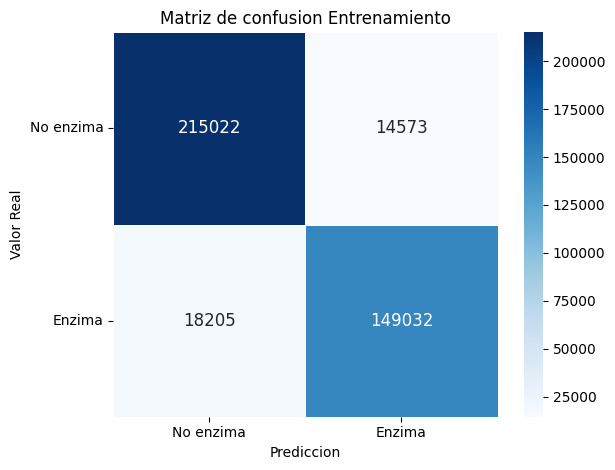

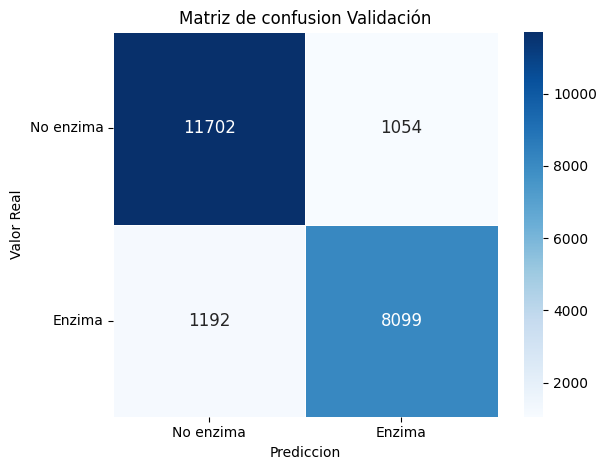

In [12]:
accuracy_t = accuracy_score(y_train, pred_train)
accuracy_v = accuracy_score(y_valid, pred_valid)
precision_t = precision_score(y_train, pred_train)
precision_v = precision_score(y_valid, pred_valid)
recall_t = recall_score(y_train, pred_train)
recall_v = recall_score(y_valid, pred_valid)
roc_auc_t = roc_auc_score(y_train, pred_train)
roc_auc_v = roc_auc_score(y_valid, pred_valid)
f1_t = f1_score(y_train, pred_train)
f1_v = f1_score(y_valid, pred_valid)
conf_matrix_t = confusion_matrix(y_train, pred_train)
conf_matrix_v = confusion_matrix(y_valid, pred_valid)
print(f"Accuracy training: {accuracy_t:.4f}")
print(f"Accuracy test: {accuracy_v:.4f}")
print(f"Precision training: {precision_t:.4f}")
print(f"Precision test: {precision_v:.4f}")
print(f"Recall training: {recall_t:.4f}")
print(f"Recall test: {recall_v:.4f}")
print(f'AUC training: {roc_auc_t:.4f}')
print(f'AUC test: {roc_auc_v:.4f}')
print(f"F1-score training: {f1_t:.4f}")
print(f"F1-score test: {f1_v:.4f}")
print("Clasification report training:", classification_report(y_train, pred_train), sep=f'\n')
print("Clasification report test:", classification_report(y_valid, pred_valid), sep=f'\n')
class_labels = ['No enzima', 'Enzima']
plot_con_matrix(conf_matrix_t, class_labels, 'Matriz de confusion Entrenamiento')
plot_con_matrix(conf_matrix_v, class_labels, 'Matriz de confusion Validación')

In [7]:
X_test = np.load(test_feat_dir)
y_test = np.load(y_test_dir)

689/689 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step
Accuracy test: 0.9026
Clasification report test:
              precision    recall  f1-score   support

           0       0.91      0.92      0.92     12755
           1       0.89      0.88      0.88      9291

    accuracy                           0.90     22046
   macro avg       0.90      0.90      0.90     22046
weighted avg       0.90      0.90      0.90     22046



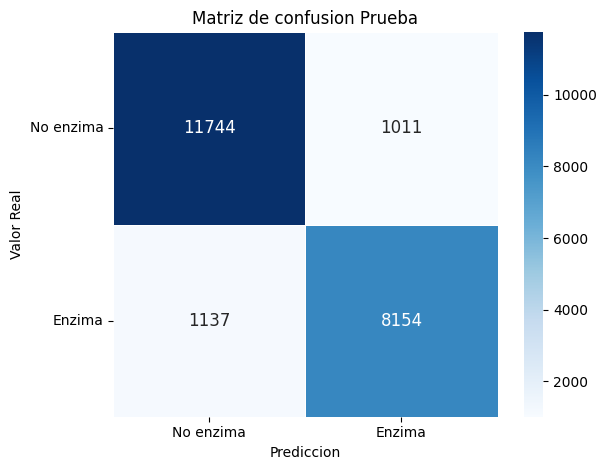

In [9]:
pred_test = model.predict(X_test)
pred_test = (pred_test > 0.5).astype(int)
y_test = y_test.reshape((-1, 1))
acc_t = accuracy_score(y_test, pred_test)
conf_matrix_t = confusion_matrix(y_test, pred_test)
class_labels = ['No enzima', 'Enzima']
print(f"Accuracy test: {acc_t:.4f}")
print("Clasification report test:", classification_report(y_test, pred_test), sep=f'\n')
plot_con_matrix(conf_matrix_t, class_labels, 'Matriz de confusion Prueba')

In [ ]:
history = pd.read_csv(str(current_dir.parent / 'notebooks/history_1l_feat.csv'))
history.head(20)

,epoch,accuracy,loss,val_accuracy,val_loss
0,0,0.819226,0.412891,0.843561,0.363905
1,1,0.857388,0.346586,0.864199,0.329713
2,2,0.873236,0.315865,0.873543,0.311884
3,3,0.882570,0.296153,0.878759,0.302824
4,4,0.889069,0.282560,0.883249,0.297162
5,5,0.893784,0.272449,0.885018,0.293030
6,6,0.897239,0.264529,0.887649,0.289943
7,7,0.900482,0.258056,0.889146,0.288585
8,8,0.902951,0.252622,0.891051,0.287104
9,9,0.905056,0.248026,0.892185,0.286413


In [14]:
from matplotlib.ticker import MaxNLocator
def plot_charts(history: pd.DataFrame, metrics: tuple[str, str], labels: tuple[str, str]):
    epochs = history['epoch'].to_numpy() + 1 if 'epoch' in history.columns else np.arange(1, len(history) + 1)

    best_val_loss_idx = history[f'val_{metrics[0]}'].idxmin()
    best_val_acc_idx = history[f'val_{metrics[1]}'].idxmax()

    train_color = '#1f77b4'
    valid_color = '#d62728'
    highlight_color = '#222222'

    sns.set_theme(style='whitegrid', context='paper')
    plt.rcParams.update({
        'font.size': 11,
        'axes.titlesize': 13,
        'axes.labelsize': 11,
        'legend.fontsize': 10,
        'xtick.labelsize': 10,
        'ytick.labelsize': 10,
        'axes.spines.top': False,
        'axes.spines.right': False,
    })

    fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), dpi=180, constrained_layout=True)

    metric_specs = [
        {
            'ax': axes[0],
            'train_key': metrics[0],
            'valid_key': f'val_{metrics[0]}',
            'title': f'{labels[0]} del entrenamiento y validación',
            'ylabel': labels[0],
            'best_idx': best_val_loss_idx,
        },
        {
            'ax': axes[1],
            'train_key': metrics[1],
            'valid_key': f'val_{metrics[1]}',
            'title': f'{labels[1]} del entrenamiento y validación',
            'ylabel': labels[1],
            'best_idx': best_val_acc_idx,
        },
    ]

    for spec in metric_specs:
        ax = spec['ax']
        train_values = history[spec['train_key']].to_numpy()
        valid_values = history[spec['valid_key']].to_numpy()
        best_epoch = int(epochs[spec['best_idx']])
        best_value = valid_values[spec['best_idx']]

        ax.plot(epochs, train_values, color=train_color, lw=2.2, label='Entrenamiento')
        ax.plot(epochs, valid_values, color=valid_color, lw=2.2, ls='--', label='Validación')
        ax.scatter(best_epoch, best_value, color=highlight_color, s=38, zorder=5)
        ax.axvline(best_epoch, color=highlight_color, lw=1.0, ls=':', alpha=0.8)
        '''
        ax.annotate(
            f"Época {best_epoch}\n{best_value:.4f}",
            xy=(best_epoch, best_value),
            xytext=(10, 12),
            textcoords='offset points',
            fontsize=9,
            color=highlight_color,
            bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#444444', alpha=0.95),
            arrowprops=dict(arrowstyle='->', color=highlight_color, lw=0.9),
        )
        '''

        ax.set_title(spec['title'], pad=10, weight='bold')
        ax.set_xlabel('Época')
        ax.set_ylabel(spec['ylabel'])
        ax.set_xlim(epochs.min(), epochs.max())
        ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        ax.grid(True, which='major', color='#d9d9d9', lw=0.8)
        ax.grid(True, which='minor', color='#efefef', lw=0.5, alpha=0.7)
        ax.minorticks_on()
        ax.tick_params(axis='both', which='major', length=5, width=0.8)
        ax.legend(loc='best', frameon=True, framealpha=0.95, edgecolor='#d0d0d0')

    axes[0].text(
        0.02,
        0.98,
        f"{labels[0]} final del entrenamiento: {history[metrics[0]].iloc[-1]:.4f}\n{labels[0]} final validación: {history[f'val_{metrics[0]}'].iloc[-1]:.4f}",
        transform=axes[0].transAxes,
        va='top',
        fontsize=9,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#d0d0d0', alpha=0.95),
    )

    axes[1].text(
        0.02,
        0.98,
        f"{labels[1]} final entrenamiento: {history[metrics[1]].iloc[-1]:.4f}\n{labels[1]} final validación: {history[f'val_{metrics[1]}'].iloc[-1]:.4f}",
        transform=axes[1].transAxes,
        va='top',
        fontsize=9,
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#d0d0d0', alpha=0.95),
    )

    fig.suptitle('Curvas de aprendizaje del modelo', fontsize=15, weight='bold', y=1.03)
    sns.despine(fig=fig)
    plt.show()

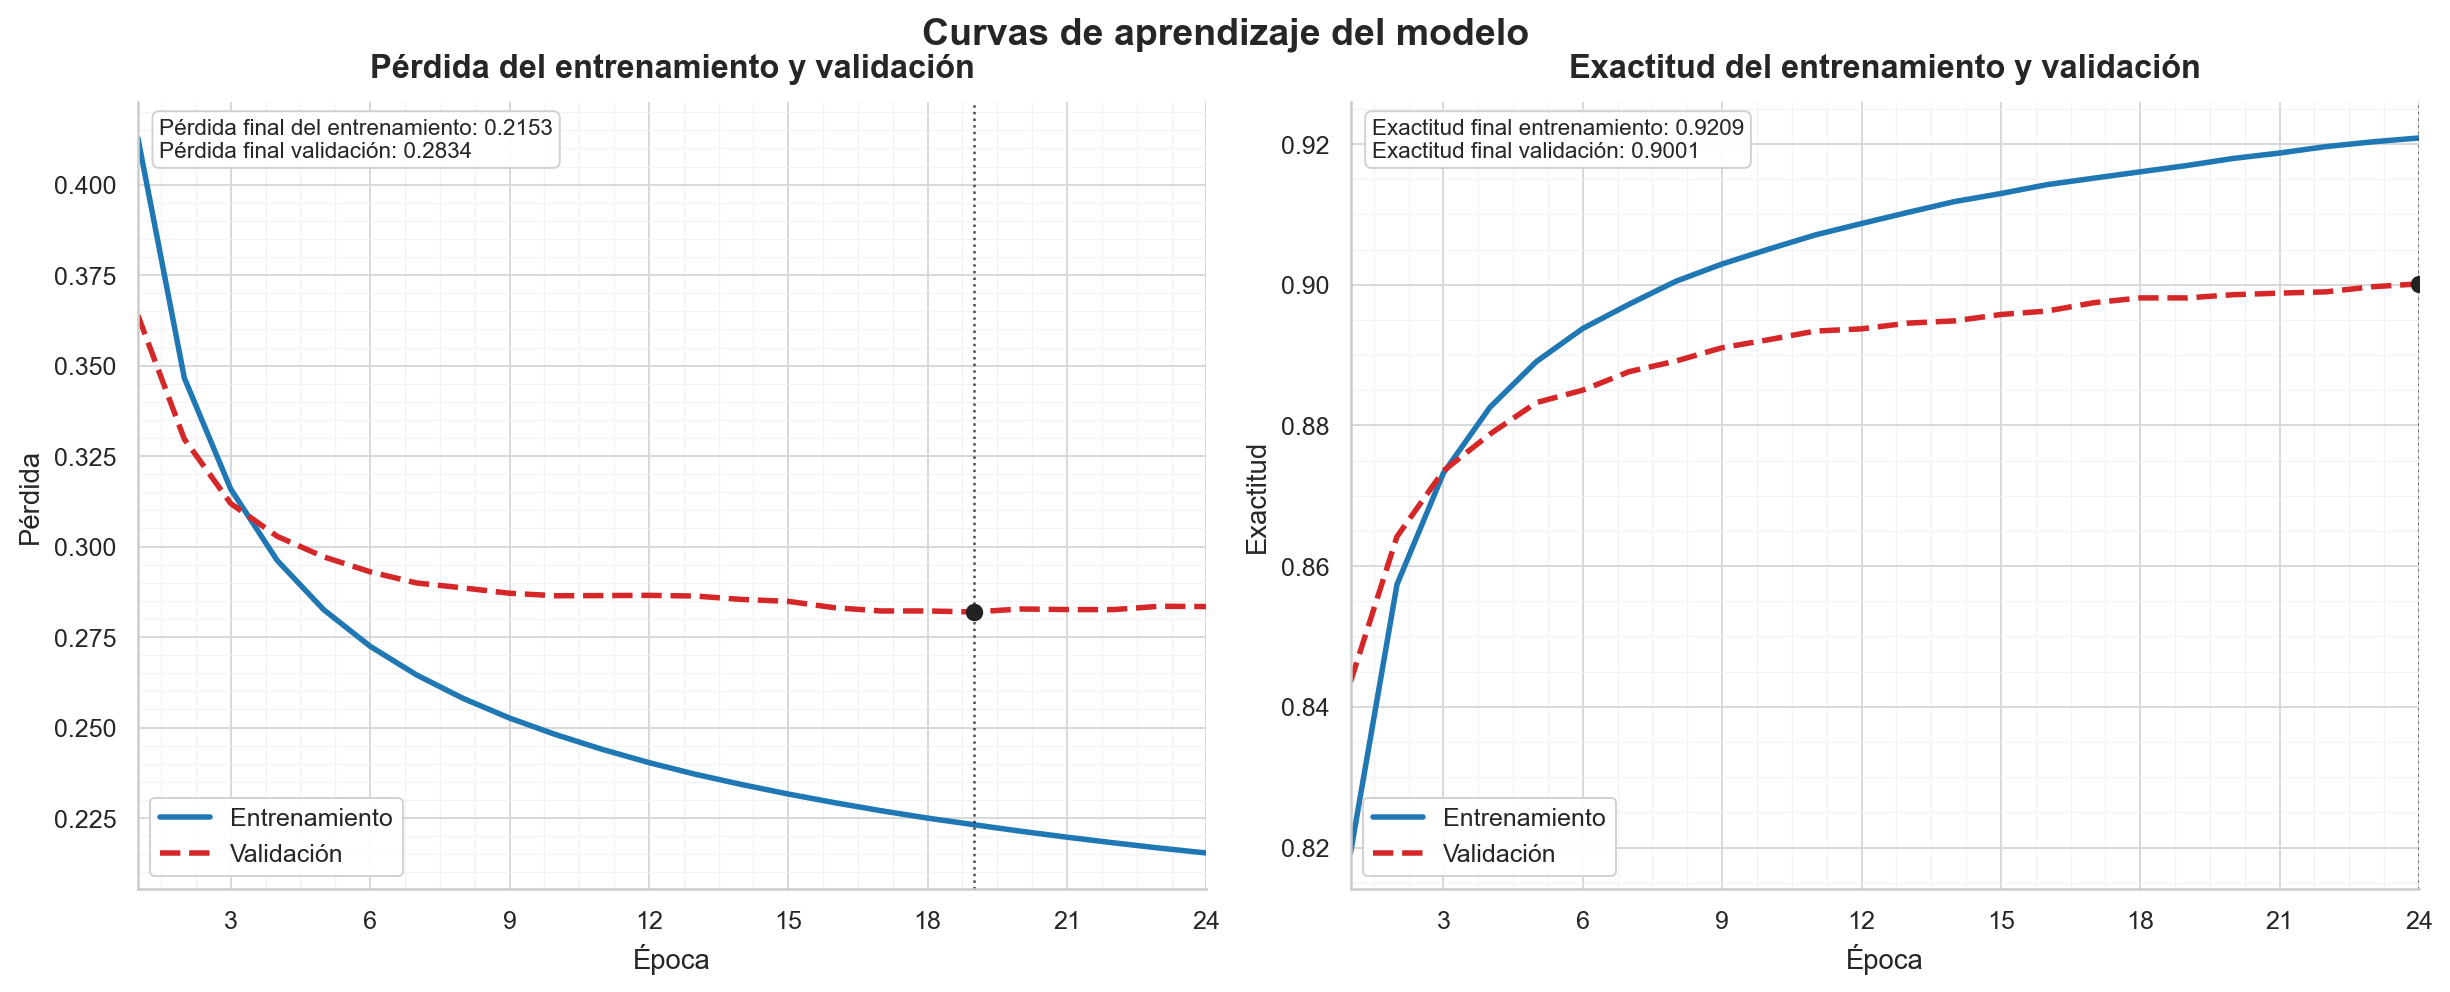

In [15]:
plot_charts(history, ('loss', 'accuracy'), ('Pérdida', 'Exactitud'))